# Fraud detection models on `gold.ml_features`

Which model ranks card frauds best, and what would it cost a fraud team in alerts?

The data is the Kaggle credit-card simulation (1.85 M transactions, 2019–2020) after its trip through the
pipeline: replayed into Kafka, cleaned into the Silver Iceberg table by Spark Structured Streaming, and turned
into one row of features per transaction by the dbt model `gold.ml_features`. Training runs on the Spark
cluster with Spark MLlib; only scores come back to this notebook.

1. Data: class balance, and where frauds concentrate
2. Split: train, validation and test in time order
3. Models: three classifiers and two baselines
4. Results: ranking quality, precision and recall at a threshold, curves, errors, features
5. Business view: alerts per day and fraud amount caught
6. Conclusions and limits

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.ml.classification import GBTClassifier, LogisticRegression, RandomForestClassifier
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from fraud_lakehouse import metrics
from fraud_lakehouse.model import (
    LABEL,
    SEED,
    check_splits,
    fraud_probability,
    pipeline,
    prepare,
    time_split,
    top_features,
    with_class_weight,
)

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

spark = (
    SparkSession.builder.appName("jupyter")
    .config("spark.driver.memory", "512m")
    .config("spark.driver.host", "jupyter")
    # Progress bars and warnings would be saved into the committed outputs.
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/27 09:54:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Data

`split` comes from the source files: `train` is fraudTrain.csv (2019-01 to 2020-06), `test` is fraudTest.csv
(2020-06 to 2020-12). The table is an Iceberg table, so the snapshot id below pins the exact data these
results were computed on.

In [2]:
ml_features = spark.table("gold.ml_features")
check_splits(dict(ml_features.groupBy("split").count().collect()))
snapshot = spark.sql(
    "SELECT snapshot_id FROM gold.ml_features.snapshots ORDER BY committed_at DESC"
).first()[0]

overview = (
    ml_features.groupBy("split")
    .agg(
        F.count("*").alias("rows"),
        F.sum(LABEL).alias("frauds"),
        F.avg(LABEL).alias("fraud_rate"),
        F.min("trans_ts").alias("first"),
        F.max("trans_ts").alias("last"),
    )
    .orderBy(F.desc("split"))
    .toPandas()
    .set_index("split")
)
print(f"gold.ml_features snapshot {snapshot}")
overview.style.format({"rows": "{:,}", "frauds": "{:,}", "fraud_rate": "{:.3%}"})

gold.ml_features snapshot 1322022991414531140


,rows,frauds,fraud_rate,first,last
split,,,,,
train,"1,296,675","7,506",0.579%,2019-01-01 00:00:18,2020-06-21 12:13:37
test,"555,719","2,145",0.386%,2020-06-21 12:14:25,2020-12-31 23:59:34


Frauds are about half a percent of transactions. Accuracy is useless here: a model that never flags anything
is 99.5 % accurate. The metrics below are about how well frauds are *ranked* above legitimate transactions.

The charts use the train split only, so nothing about the test period leaks into choices made here.

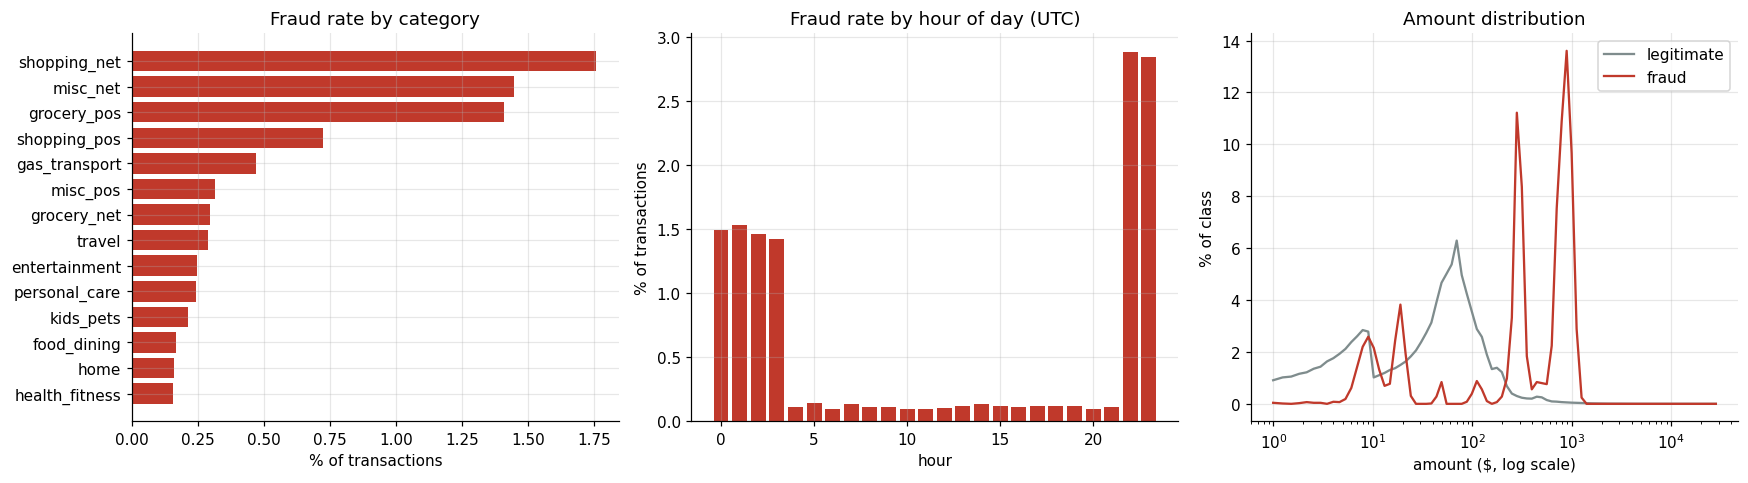

In [3]:
train_rows = ml_features.where("split = 'train'")
by_category = (
    train_rows.groupBy("category")
    .agg(F.avg(LABEL).alias("fraud_rate"))
    .toPandas()
    .sort_values("fraud_rate")
)
by_hour = (
    train_rows.groupBy("hour_of_day")
    .agg(F.avg(LABEL).alias("fraud_rate"))
    .toPandas()
    .sort_values("hour_of_day")
)
# Amounts binned on a log scale in Spark: 20 bins per power of ten.
amount_bins = (
    train_rows.groupBy(LABEL, F.floor(F.log10(F.col("amt") + 1) * 20).alias("bin"))
    .count()
    .toPandas()
    .pivot(index="bin", columns=LABEL, values="count")
    .fillna(0)
    .sort_index()
)
amount_share = amount_bins / amount_bins.sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].barh(by_category["category"], by_category["fraud_rate"] * 100, color="#c0392b")
axes[0].set(title="Fraud rate by category", xlabel="% of transactions")
axes[1].bar(by_hour["hour_of_day"], by_hour["fraud_rate"] * 100, color="#c0392b")
axes[1].set(title="Fraud rate by hour of day (UTC)", xlabel="hour", ylabel="% of transactions")
amounts = 10 ** (amount_share.index / 20) - 1
axes[2].plot(amounts, amount_share[0] * 100, label="legitimate", color="#7f8c8d")
axes[2].plot(amounts, amount_share[1] * 100, label="fraud", color="#c0392b")
axes[2].set(
    title="Amount distribution", xlabel="amount ($, log scale)", ylabel="% of class", xscale="log"
)
axes[2].legend()
fig.tight_layout()
fig.savefig(FIGURES / "data_overview.png", bbox_inches="tight")

## 2. Split

Fraud patterns drift, so a random split would let the model learn from the future. Everything here is in
time order:

| split | rows | used for |
|---|---|---|
| fit | first 80 % of `train` | fitting the models |
| validation | last 20 % of `train` | choosing each model's decision threshold |
| test | all of `test` | the reported numbers, touched once |

Frauds get a class weight so that each class carries half of the training weight; without it the models learn
that "never fraud" is nearly always right.

In [4]:
fit, validation = time_split(prepare(train_rows), validation_fraction=0.2)
fit = with_class_weight(fit).cache()
validation = validation.cache()
test = prepare(ml_features.where("split = 'test'")).cache()

sizes = pd.DataFrame(
    [
        {"split": name, "rows": df.count(), "fraud_rate": df.agg(F.avg(LABEL)).first()[0]}
        for name, df in [("fit", fit), ("validation", validation), ("test", test)]
    ]
).set_index("split")
sizes.style.format({"rows": "{:,}", "fraud_rate": "{:.3%}"})

,rows,fraud_rate
split,,
fit,"1,037,339",0.575%
validation,"259,336",0.593%
test,"555,719",0.386%


## 3. Models

| model | why it is here |
|---|---|
| Random | the floor: its PR-AUC equals the fraud rate |
| Amount only | a one-rule baseline: flag the largest transactions |
| Logistic regression | linear, fast, easy to explain |
| Random forest | non-linear, robust to feature scale |
| Gradient-boosted trees | usually the strongest on tabular data |

All three classifiers share the same pipeline: the numeric features from `gold.ml_features` plus a one-hot
`category`. Hyperparameters are fixed and modest; there is no search, so the comparison is about model
families on equal footing.

In [5]:
CLASSIFIERS = {
    "Logistic regression": LogisticRegression(labelCol=LABEL, weightCol="weight", maxIter=100),
    "Random forest": RandomForestClassifier(
        labelCol=LABEL, weightCol="weight", numTrees=60, maxDepth=10, seed=SEED
    ),
    "Gradient-boosted trees": GBTClassifier(
        labelCol=LABEL, weightCol="weight", maxIter=50, maxDepth=5, seed=SEED
    ),
}
SCORED = [LABEL, "p_fraud", "amt"]


def scores(model, df):
    return fraud_probability(model.transform(df)).select(*SCORED).toPandas()


models, train_seconds, validation_scores, test_scores = {}, {}, {}, {}
for name, classifier in CLASSIFIERS.items():
    start = time.perf_counter()
    models[name] = pipeline(classifier).fit(fit)
    train_seconds[name] = time.perf_counter() - start
    validation_scores[name] = scores(models[name], validation)
    test_scores[name] = scores(models[name], test)
    print(f"{name:24} trained in {train_seconds[name]:4.0f} s")

rng = np.random.default_rng(SEED)
for frames in (validation_scores, test_scores):
    labelled = frames["Logistic regression"][[LABEL, "amt"]]
    frames["Random"] = labelled.assign(p_fraud=rng.random(len(labelled)))
    frames["Amount only"] = labelled.assign(p_fraud=labelled["amt"])

Logistic regression      trained in   11 s


Random forest            trained in   81 s


Gradient-boosted trees   trained in  108 s


## 4. Results

- **PR-AUC** (average precision): how well frauds are ranked above legitimate transactions, over every
  threshold. The headline number for rare classes.
- **ROC-AUC**: the chance that a random fraud scores above a random legitimate transaction. It looks high
  for every decent model when frauds are rare, so it is shown but not used to rank.
- **Precision, recall, F1** at one threshold: the threshold with the best F1 on *validation*, then applied
  unchanged to test.

In [6]:
NAMES = ["Random", "Amount only", *CLASSIFIERS]


def arrays(frame):
    return frame[LABEL].to_numpy(), frame["p_fraud"].to_numpy()


rows = []
for name in NAMES:
    labels, scored = arrays(test_scores[name])
    threshold = metrics.best_threshold(*arrays(validation_scores[name]))
    rows.append(
        {
            "model": name,
            "pr_auc": metrics.average_precision(labels, scored),
            "roc_auc": metrics.roc_auc(labels, scored),
            **metrics.summary(labels, scored, threshold),
            "threshold": threshold,
            "train_s": train_seconds.get(name, np.nan),
        }
    )
results = pd.DataFrame(rows).set_index("model")
QUALITY = ["pr_auc", "roc_auc", "precision", "recall", "f1"]
(
    results[[*QUALITY, "threshold", "train_s"]]
    .style.format({**{c: "{:.3f}" for c in QUALITY}, "threshold": "{:.3g}", "train_s": "{:.0f}"})
    .highlight_max(subset=QUALITY, color="#d5f5e3")
)

,pr_auc,roc_auc,precision,recall,f1,threshold,train_s
model,,,,,,,
Random,0.004,0.506,0.005,0.021,0.008,0.982,nan
Amount only,0.137,0.833,0.290,0.445,0.351,707,nan
Logistic regression,0.187,0.963,0.280,0.536,0.368,0.954,11
Random forest,0.910,0.996,0.869,0.837,0.853,0.855,81
Gradient-boosted trees,0.867,0.996,0.858,0.791,0.823,0.964,108


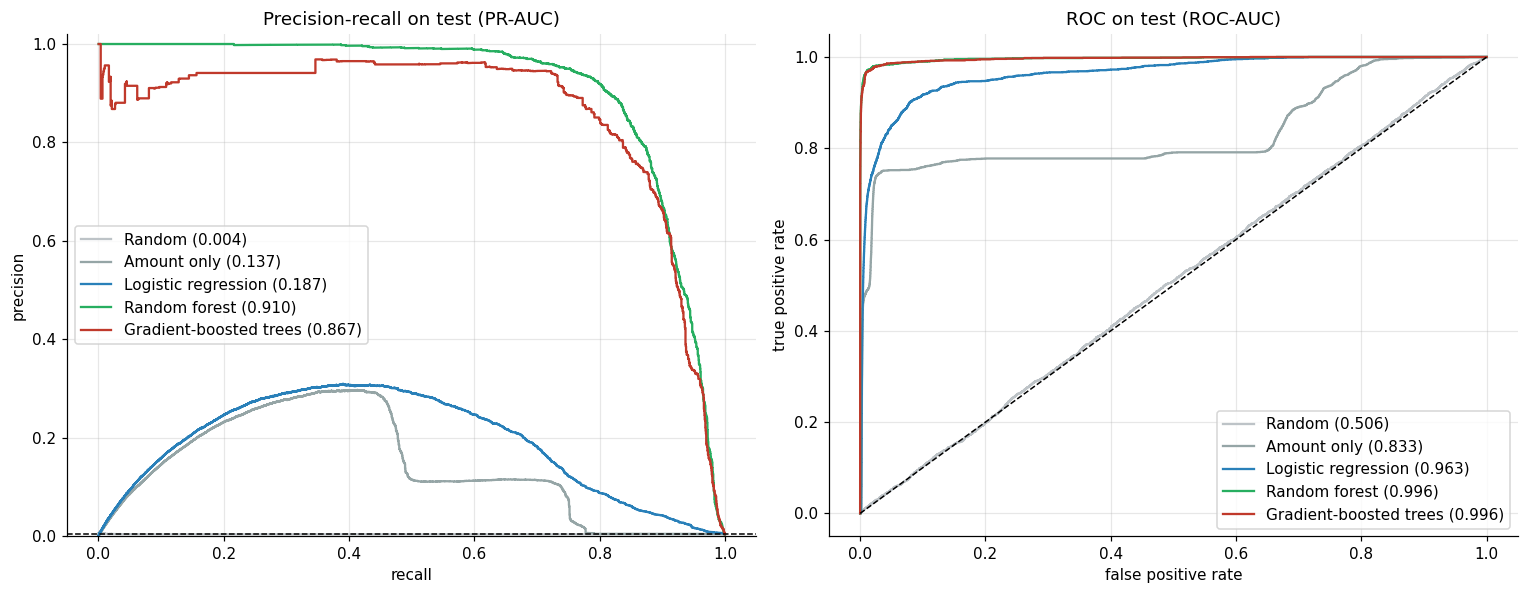

In [7]:
COLORS = dict(zip(NAMES, ["#bdc3c7", "#95a5a6", "#2980b9", "#27ae60", "#c0392b"], strict=True))
fraud_rate = overview.loc["test", "fraud_rate"]

fig, (pr_ax, roc_ax) = plt.subplots(1, 2, figsize=(14, 5.5))
for name in NAMES:
    labels, scored = arrays(test_scores[name])
    precision, recall, _ = metrics.pr_curve(labels, scored)
    fpr, tpr = metrics.roc_curve(labels, scored)
    label = f"{name} ({results.loc[name, 'pr_auc']:.3f})"
    pr_ax.step(recall, precision, where="post", color=COLORS[name], label=label)
    roc_ax.plot(fpr, tpr, color=COLORS[name], label=f"{name} ({results.loc[name, 'roc_auc']:.3f})")
pr_ax.axhline(fraud_rate, ls="--", lw=1, color="black")
pr_ax.set(
    title="Precision-recall on test (PR-AUC)", xlabel="recall", ylabel="precision", ylim=(0, 1.02)
)
roc_ax.plot([0, 1], [0, 1], ls="--", lw=1, color="black")
roc_ax.set(title="ROC on test (ROC-AUC)", xlabel="false positive rate", ylabel="true positive rate")
pr_ax.legend(loc="center left")
roc_ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "pr_roc_curves.png", bbox_inches="tight")

### Errors at the chosen threshold

Each matrix counts test transactions. Top right are false alarms an analyst would review for nothing; bottom
left are frauds that got through.

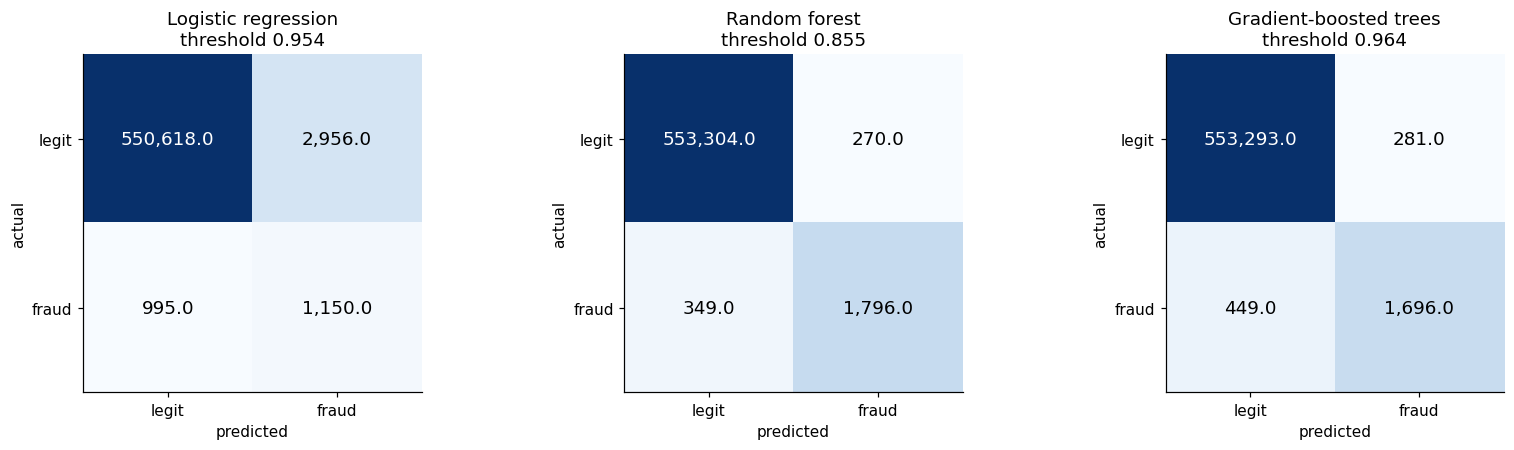

In [8]:
fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(15, 4.2))
for ax, name in zip(axes, CLASSIFIERS, strict=True):
    r = results.loc[name]
    matrix = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(np.log10(matrix + 1), cmap="Blues")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(
            j,
            i,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=12,
            color="white" if i == j == 0 else "black",
        )
    ax.set(
        title=f"{name}\nthreshold {r.threshold:.3g}",
        xticks=[0, 1],
        xticklabels=["legit", "fraud"],
        xlabel="predicted",
        yticks=[0, 1],
        yticklabels=["legit", "fraud"],
        ylabel="actual",
    )
    ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURES / "confusion_matrices.png", bbox_inches="tight")

### What the tree models look at

Impurity-based importances of the two tree ensembles, top 10 features each. `category_vec_*` is one
category of the one-hot `category`.

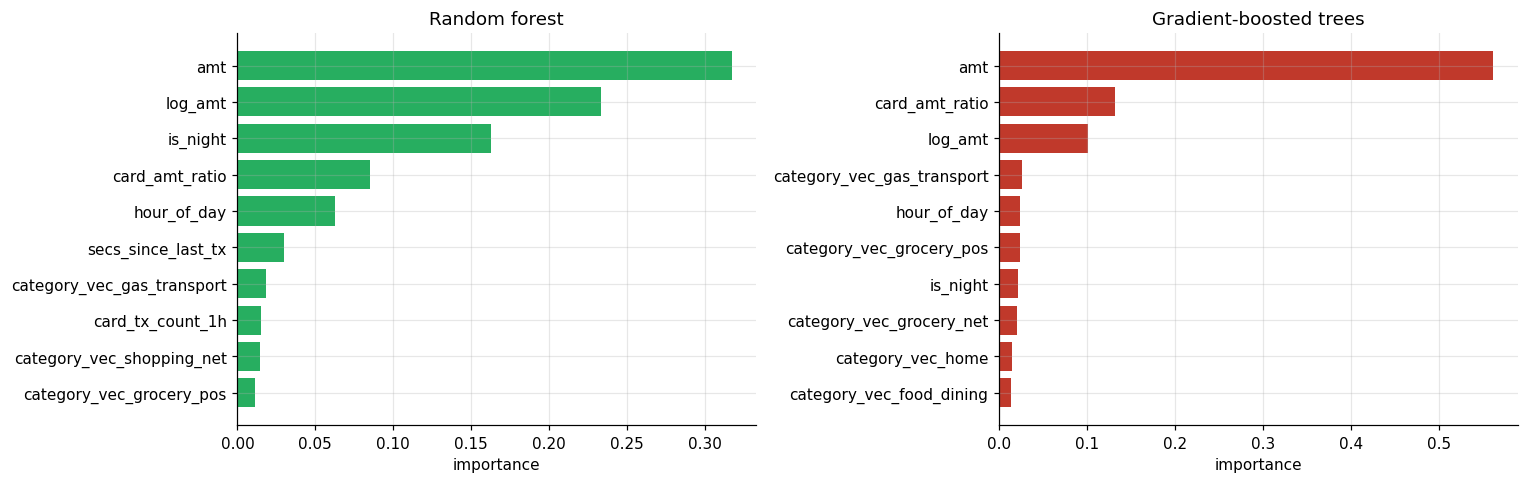

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, ["Random forest", "Gradient-boosted trees"], strict=True):
    model = models[name]
    top = top_features(model, model.transform(test.limit(1)), 10)[::-1]
    ax.barh([feature for feature, _ in top], [weight for _, weight in top], color=COLORS[name])
    ax.set(title=name, xlabel="importance")
fig.tight_layout()
fig.savefig(FIGURES / "feature_importance.png", bbox_inches="tight")

## 5. Business view

The same thresholds, read as a fraud team would: how many alerts a day the team must review, what share of
alerts are real frauds, and what share of the fraud *amount* is stopped.

In [10]:
test_days = (overview.loc["test", "last"] - overview.loc["test", "first"]).total_seconds() / 86400
business = []
for name in NAMES:
    frame = test_scores[name]
    flagged = frame["p_fraud"] >= results.loc[name, "threshold"]
    fraud = frame[LABEL] == 1
    business.append(
        {
            "model": name,
            "alerts_per_day": flagged.sum() / test_days,
            "alerts_that_are_fraud": results.loc[name, "precision"],
            "frauds_caught": int((flagged & fraud).sum()),
            "frauds_missed": int((~flagged & fraud).sum()),
            "fraud_amount_caught": frame.loc[flagged & fraud, "amt"].sum()
            / frame.loc[fraud, "amt"].sum(),
        }
    )
pd.DataFrame(business).set_index("model").style.format(
    {
        "alerts_per_day": "{:,.0f}",
        "alerts_that_are_fraud": "{:.1%}",
        "frauds_caught": "{:,}",
        "frauds_missed": "{:,}",
        "fraud_amount_caught": "{:.1%}",
    }
)

,alerts_per_day,alerts_that_are_fraud,frauds_caught,frauds_missed,fraud_amount_caught
model,,,,,
Random,52,0.5%,46,"2,099",2.1%
Amount only,17,29.0%,954,"1,191",78.3%
Logistic regression,21,28.0%,"1,150",995,84.7%
Random forest,11,86.9%,"1,796",349,92.3%
Gradient-boosted trees,10,85.8%,"1,696",449,89.2%


## 6. Conclusions

- **Tree ensembles win by far.** Random forest reaches a PR-AUC of 0.910 and gradient-boosted trees 0.867, against
  0.187 for logistic regression and 0.137 for the amount-only rule. ROC-AUC (0.996 for both ensembles, 0.963 for
  logistic regression) hides most of that gap, which is why PR-AUC ranks the models.
- **At its validation threshold, random forest** raises about 11 alerts a day, 86.9 % of them real frauds. It catches
  83.7 % of the test frauds and 92.3 % of the fraud amount.
- **Why a linear model falls short.** Frauds cluster in amount bands (around \$300 and \$1,000, with a smaller peak
  near \$20) and at night (22:00 to 03:59 UTC). Fraud risk does not rise steadily with any one feature, so a linear
  score cannot isolate those bands; trees split on them directly.
- **What the trees use.** The amount dominates both ensembles (`amt`, `log_amt`), followed by how unusual the amount is
  for the card (`card_amt_ratio`) and the time of day (`is_night`, `hour_of_day`). Velocity features
  (`card_tx_count_1h`, `secs_since_last_tx`) weigh little.

Limits:

- The data is simulated: its patterns are cleaner than real card traffic, so scores this high would not transfer.
- One time split and fixed hyperparameters, with no search: the 0.04 PR-AUC gap between the two ensembles is within
  what tuning could change.
- Thresholds maximise F1. A fraud team would set its own from its alert budget and the cost of a missed fraud.